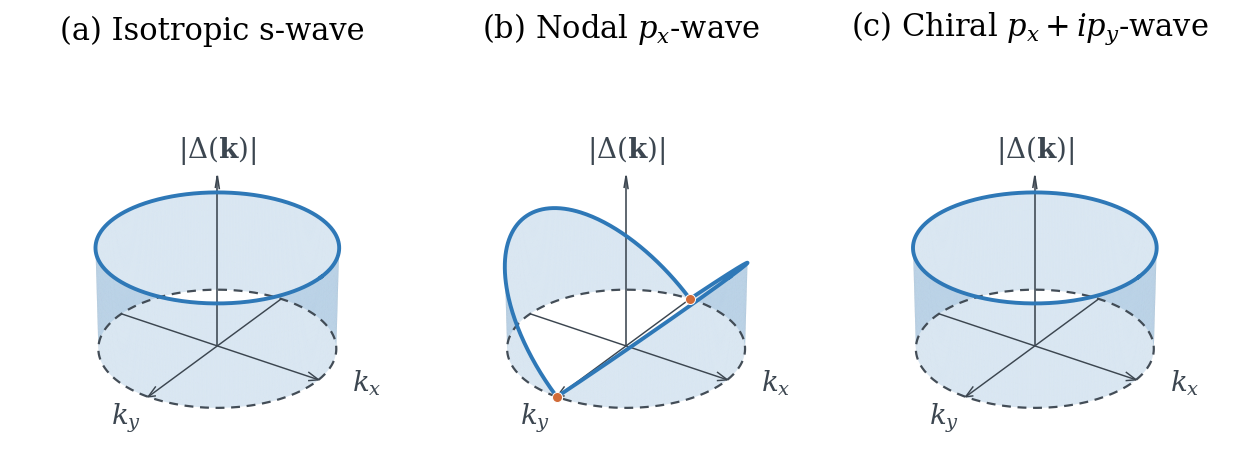

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

DELTA0 = 0.62
KF = 1.0
ELEVATION = 27
AZIMUTH = -56

BLUE = "#2E78B7"
ORANGE = "#D16B38"
GREY = "#3C4650"
INK = "#3C4650"

rcParams.update({
    "font.family": "DejaVu Serif",
    "mathtext.fontset": "dejavuserif",
    "font.size": 12,
    "svg.fonttype": "none",
    "savefig.facecolor": "white",
})


theta = np.linspace(0, 2*np.pi, 481)
x = KF*np.cos(theta)
y = KF*np.sin(theta)


profiles = [
    (r"(a) Isotropic s-wave",       lambda t: DELTA0*np.ones_like(t)),
    (r"(b) Nodal $p_x$-wave",           lambda t: DELTA0*np.abs(np.cos(t))),
    (r"(c) Chiral $p_x+ip_y$-wave",    lambda t: DELTA0*np.ones_like(t)),
]

fig = plt.figure(figsize=(12.65, 4.25), facecolor="white")

for i, (title, gap_fn) in enumerate(profiles, start=1):
    ax = fig.add_subplot(1, 3, i, projection="3d", computed_zorder=False)
    gap = gap_fn(theta)


    heights = np.linspace(0, 1, 18)
    X = x[:, None]*np.ones((1, len(heights)))
    Y = y[:, None]*np.ones((1, len(heights)))
    Z = gap[:, None]*heights[None, :]
    ax.plot_surface(X, Y, Z, color=BLUE, alpha=0.18, linewidth=0,
                    edgecolor="none", antialiased=True, shade=False,
                    rcount=len(theta), ccount=len(heights), zorder=1)


    ax.plot(x, y, np.zeros_like(theta), linestyle=(0, (4, 3)),
            linewidth=1.6, color=GREY, alpha=0.96, zorder=5)
    ax.plot(x, y, gap, linewidth=2.8, color=BLUE, zorder=6)


    if i == 2:
        ax.scatter([0, 0], [KF, -KF], [0, 0],
                   s=52, color=ORANGE, depthshade=False,
                   edgecolors="white", linewidths=0.7, zorder=8)


    extent = KF
    ax.quiver(-extent, 0, 0, 2.*extent, 0, 0,
              color=INK, linewidth=1.05, arrow_length_ratio=0.052)

    ax.quiver(0, extent, 0, 0, -2.*extent, 0,
              color=INK, linewidth=1.05, arrow_length_ratio=0.056)
    ax.quiver(0, 0, 0, 0, 0, 1.03,
              color=INK, linewidth=1.15, arrow_length_ratio=0.075)

    ax.text(1.2*extent + 0.12, 0, 0, r"$k_x$", color=INK, fontsize=20)
    ax.text(0, -1.2*extent - 0.3, 0, r"$k_y$", color=INK, fontsize=20)
    ax.text(-0., 0., 1.14, r"$|\Delta(\mathbf{k})|$", color=INK,
             fontsize=20, ha="center")

    ax.set(xlim=(-1.57, 1.57), ylim=(-1.57, 1.57), zlim=(0, 1.27))
    ax.set_box_aspect((3.14, 3.14, 1.95), zoom=1.42)
    ax.view_init(elev=ELEVATION, azim=AZIMUTH)
    ax.set_axis_off()
    ax.set_title(title, fontsize=22, pad=-6)

fig.subplots_adjust(left=0.005, right=0.995, top=0.95, bottom=0.0, wspace=-0.06)
plt.show(fig)
plt.close(fig)

